# 03 — Mejoras: búsqueda local sobre el Gbest

Notebook de la **etapa 2**. Lee `results/runs.csv` y `results/curves.npz` (no vuelve a
correr experimentos) y produce las tablas y figuras del póster.

**30 corridas independientes × 7 bases × 6 configuraciones = 1,260 corridas.**
La corrida *r* usa la misma partición (`seed=r`) y el mismo generador (`1000 + r`) en
todas las configuraciones, así que el Wilcoxon es **pareado**.

| Configuración | Qué es |
|---|---|
| `bpso` | BPSO estándar (sección 2 del artículo), línea base |
| `cbpso_miws` | **la réplica** (Algoritmo 1), referencia de todas las pruebas |
| `cbpso_miws_v` | mejora 1: función de transferencia en V, `V(v) = \|tanh v\|` |
| `cbpso_miws_ls` | **mejora 2**: réplica + búsqueda local (bit-flip, primera mejora) |
| `cbpso_miws_v_ls` | mejoras 1 + 2 juntas |
| `cbpso_miws_T150` | **control de presupuesto**: la réplica con `T = 150` para igualar evaluaciones |

Contenido:

1. Tabla resumen (media ± desv., mediana)
2. Wilcoxon pareado contra la réplica
3. Boxplots del fitness de las 30 corridas
4. Curvas de convergencia **por evaluaciones** (no por iteraciones)
5. Conclusión

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from bfs.experiment import METHODS, curve_key
from bfs.stats import compare_all, pvalue_matrix, summarize, summary_table

RESULTS = Path("..") / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RESULTS / "runs.csv")
curvas = {k: v for k, v in np.load(RESULTS / "curves.npz").items()}

# Orden fijo para todas las tablas y figuras del póster
ORDEN = list(METHODS)
# Bases ordenadas por número de variables: ahí está la historia
DIMS = {"breast_cancer_wisconsin": 9, "glass": 9, "breast_cancer_coimbra": 9,
        "glass_id": 10, "ionosphere": 34, "lung_cancer": 56, "libras": 90}
BASES = sorted(DIMS, key=lambda d: (DIMS[d], d))
ETIQUETA = {m: m.replace("cbpso_miws", "CBPSO").replace("bpso", "BPSO") for m in ORDEN}
COLOR = dict(zip(ORDEN, ["tab:gray", "tab:blue", "tab:orange", "tab:green",
                         "tab:red", "tab:purple"]))

df["method"] = pd.Categorical(df["method"], categories=ORDEN, ordered=True)
df["dataset"] = pd.Categorical(df["dataset"], categories=BASES, ordered=True)

print(f"{len(df)} filas · {df['run'].nunique()} corridas · "
      f"{df['dataset'].nunique()} bases · {df['method'].nunique()} configuraciones")
print("corridas por (base, método):", sorted(df.groupby(['dataset','method'], observed=True).size().unique()))

1260 filas · 30 corridas · 7 bases · 6 configuraciones
corridas por (base, método): [np.int64(30)]


## 1. Tabla resumen

Media ± desviación estándar (y mediana entre paréntesis) de las 30 corridas.
`n_evals` es el costo: lo que cada configuración le pide a la función de fitness.

In [2]:
pd.set_option("display.width", 220, "display.max_columns", 50)

resumen = summarize(df)
resumen.round(4).to_csv(RESULTS / "resumen.csv")
resumen[[("accuracy", "mean"), ("accuracy", "std"), ("best_fitness", "mean"),
         ("best_fitness", "std"), ("n_features", "mean"), ("n_evals", "mean")]].round(4)

accuracy         best_fitness         n_features    n_evals
                                            mean     std         mean     std       mean       mean
dataset                 method                                                                     
breast_cancer_coimbra   bpso             87.9167  4.8133       0.1240  0.0473     3.9333  1010.0000
                        cbpso_miws       88.4722  4.4694       0.1185  0.0438     3.9667  1010.0000
                        cbpso_miws_v     86.5278  5.2114       0.1384  0.0509     4.5000  1010.0000
                        cbpso_miws_ls    88.6111  4.3678       0.1172  0.0428     4.0333  1507.2000
                        cbpso_miws_v_ls  87.2222  5.1246       0.1312  0.0501     4.2333  1507.9000
                        cbpso_miws_T150  88.4722  4.3334       0.1186  0.0425     4.0333  1510.0000
breast_cancer_wisconsin bpso             97.9524  1.0228       0.0249  0.0098     4.2000  1010.0000
                        cbpso_miws       97.9762  0.9941       0.0248  0.0095     4.3000  1010.0000
                        cbpso_miws_v     97.6190  0.9253       0.0284  0.0090     4.3667  1010.0000
                        cbpso_miws_ls    97.9524  0.9699       0.0249  0.0094     4.2000  1507.1333
                        cbpso_miws_v_ls  97.7857  0.9256       0.0270  0.0089     4.6000  1507.0667
                        cbpso_miws_T150  97.9762  0.9941       0.0249  0.0095     4.3333  1510.0000
glass                   bpso             79.0698  4.5703       0.2117  0.0450     4.0667  1010.0000
                        cbpso_miws       79.6124  4.3479       0.2067  0.0429     4.3333  1010.0000
                        cbpso_miws_v     77.5194  4.2018       0.2275  0.0416     4.4667  1010.0000
                        cbpso_miws_ls    79.3798  4.3070       0.2090  0.0427     4.3667  1506.0667
                        cbpso_miws_v_ls  78.4496  4.4851       0.2181  0.0443     4.3000  1506.9000
                        cbpso_miws_T150  79.6124  4.3479       0.2067  0.0430     4.3667  1510.0000
glass_id                bpso             98.9147  1.3287       0.0121  0.0131     1.3667  1010.0000
                        cbpso_miws       98.9147  1.3287       0.0122  0.0130     1.5000  1010.0000
                        cbpso_miws_v     97.1318  2.4186       0.0311  0.0243     2.7000  1010.0000
                        cbpso_miws_ls    98.9147  1.3287       0.0121  0.0131     1.4000  1505.2667
                        cbpso_miws_v_ls  98.2171  1.5789       0.0199  0.0164     2.2667  1505.0667
                        cbpso_miws_T150  98.9147  1.3287       0.0121  0.0131     1.3667  1510.0000
ionosphere              bpso             94.1315  2.1275       0.0611  0.0212    10.1667  1010.0000
                        cbpso_miws       94.5540  2.4460       0.0568  0.0240     9.9667  1010.0000
                        cbpso_miws_v     92.7700  3.0441       0.0752  0.0302    12.3000  1010.0000
                        cbpso_miws_ls    95.6338  2.2605       0.0456  0.0223     8.1333  1488.0000
                        cbpso_miws_v_ls  95.2113  2.4977       0.0499  0.0250     8.5000  1485.5667
                        cbpso_miws_T150  94.7887  2.3143       0.0545  0.0228     9.8667  1510.0000
lung_cancer             bpso             94.2857  8.0463       0.0601  0.0796    19.6333  1010.0000
                        cbpso_miws       93.3333  7.2488       0.0693  0.0717    18.6000  1010.0000
                        cbpso_miws_v     90.9524  8.7850       0.0933  0.0869    20.9667  1010.0000
                        cbpso_miws_ls    96.1905  6.4254       0.0393  0.0636     8.8000  1466.8333
                        cbpso_miws_v_ls  94.7619  7.9436       0.0538  0.0784    10.8000  1468.0333
                        cbpso_miws_T150  94.2857  7.1182       0.0597  0.0704    17.7333  1510.0000
libras                  bpso             82.4537  5.3167       0.1779  0.0525    37.9333  1010.0000
                        cbpso_miws      

In [3]:
for metrica, dec in [("accuracy", 2), ("best_fitness", 4), ("n_features", 1), ("n_evals", 0)]:
    print(f"\n--- {metrica}: media ± desv. (mediana) ---")
    print(summary_table(df, metrica, decimals=dec).to_string())


--- accuracy: media ± desv. (mediana) ---
method                                   bpso            cbpso_miws          cbpso_miws_v         cbpso_miws_ls       cbpso_miws_v_ls       cbpso_miws_T150
dataset                                                                                                                                                    
breast_cancer_coimbra     87.92 ± 4.81 (87.5)   88.47 ± 4.47 (87.5)   86.53 ± 5.21 (87.5)   88.61 ± 4.37 (87.5)   87.22 ± 5.12 (87.5)   88.47 ± 4.33 (87.5)
breast_cancer_wisconsin  97.95 ± 1.02 (97.86)  97.98 ± 0.99 (97.86)   97.62 ± 0.93 (97.5)  97.95 ± 0.97 (97.86)  97.79 ± 0.93 (97.86)  97.98 ± 0.99 (97.86)
glass                    79.07 ± 4.57 (79.07)  79.61 ± 4.35 (79.07)   77.52 ± 4.2 (76.74)  79.38 ± 4.31 (79.07)  78.45 ± 4.49 (76.74)  79.61 ± 4.35 (79.07)
glass_id                 98.91 ± 1.33 (100.0)  98.91 ± 1.33 (100.0)  97.13 ± 2.42 (97.67)  98.91 ± 1.33 (100.0)  98.22 ± 1.58 (97.67)  98.91 ± 1.33 (100.0)
ionosphere           

## 2. Wilcoxon pareado contra la réplica

Prueba de los rangos con signo, pareada por corrida, con **referencia `cbpso_miws`**.
`resultado` es desde el punto de vista del retador: *mejor* / *peor* / *empate* ($\alpha = 0.05$).

Se reporta también `p_holm`, el p-valor corregido por **Holm-Bonferroni** dentro de cada
métrica (7 bases × 5 retadores = 35 comparaciones). Es la lectura conservadora: una
mejora que sobrevive a Holm no es producto de hacer muchas pruebas.

En las bases de 9 variables casi todas las diferencias son **cero** (todas las variantes
llegan al mismo óptimo): ahí la prueba no aplica y se reporta `p = 1`, empate.

In [4]:
comparaciones = compare_all(df)
comparaciones.to_csv(RESULTS / "wilcoxon.csv", index=False)

for metrica in ("best_fitness", "accuracy"):
    print(f"\n===== {metrica} — referencia cbpso_miws =====")
    sub = comparaciones[comparaciones["metric"] == metrica]
    tabla = sub.pivot(index="dataset", columns="method", values="resultado_holm")
    print(tabla.reindex(index=BASES, columns=[m for m in ORDEN if m != "cbpso_miws"]).to_string())


===== best_fitness — referencia cbpso_miws =====
method                     bpso cbpso_miws_v cbpso_miws_ls cbpso_miws_v_ls cbpso_miws_T150
dataset                                                                                   
breast_cancer_coimbra    empate         peor        empate            peor          empate
breast_cancer_wisconsin  empate         peor        empate            peor          empate
glass                    empate         peor        empate            peor          empate
glass_id                 empate         peor        empate          empate          empate
ionosphere               empate         peor         mejor          empate          empate
lung_cancer              empate         peor         mejor           mejor          empate
libras                   empate       empate         mejor           mejor          empate

===== accuracy — referencia cbpso_miws =====
method                     bpso cbpso_miws_v cbpso_miws_ls cbpso_miws_v_ls cbpso_miws

In [5]:
# p-valores crudos y corregidos, con la marca de resultado
RETADORES = [m for m in ORDEN if m != "cbpso_miws"]
MARCA = {"mejor": "+", "peor": "-", "empate": "="}

for metrica in ("best_fitness", "accuracy"):
    sub = comparaciones[comparaciones["metric"] == metrica]
    celdas = sub.assign(
        celda=sub["p_holm"].map("{:.1e}".format) + " " + sub["resultado_holm"].map(MARCA)
    ).pivot(index="dataset", columns="method", values="celda")
    print(f"\n===== {metrica}: p de Holm y marca (+ mejor, - peor, = empate) =====")
    print(celdas.reindex(index=BASES, columns=RETADORES).to_string())


===== best_fitness: p de Holm y marca (+ mejor, - peor, = empate) =====
method                        bpso cbpso_miws_v cbpso_miws_ls cbpso_miws_v_ls cbpso_miws_T150
dataset                                                                                      
breast_cancer_coimbra    1.0e+00 =    2.5e-03 -     1.0e+00 =       1.6e-02 -       1.0e+00 =
breast_cancer_wisconsin  1.0e+00 =    2.5e-03 -     1.0e+00 =       2.3e-02 -       1.0e+00 =
glass                    2.8e-01 =    2.4e-03 -     1.0e+00 =       2.3e-02 -       1.0e+00 =
glass_id                 1.0e+00 =    1.9e-03 -     1.0e+00 =       5.1e-02 =       1.0e+00 =
ionosphere               1.0e+00 =    6.4e-04 -     1.9e-03 +       1.0e+00 =       1.0e+00 =
lung_cancer              1.0e+00 =    7.8e-04 -     2.6e-03 +       2.3e-02 +       3.3e-01 =
libras                   1.0e+00 =    1.2e-01 =     1.1e-05 +       2.9e-03 +       1.9e-01 =

===== accuracy: p de Holm y marca (+ mejor, - peor, = empate) =====
method      

### Lectura de la tabla

- **`cbpso_miws_ls` (mejora 2)** gana en `ionosphere`, `lung_cancer` y `libras` —
  las tres bases con 34, 56 y 90 variables— y **sobrevive a Holm**. En las de 9–10
  variables empata, porque ahí todas las variantes ya alcanzan el mismo óptimo.
- **`cbpso_miws_T150` (control de presupuesto)** *no* gana después de Holm en ninguna
  base. Esto es lo importante: la ventaja de la mejora 2 **no viene de gastar más
  evaluaciones**, sino de cómo las gasta.
- **`cbpso_miws_v` (mejora 1)** pierde en casi todas las bases, como ya se había visto
  en la etapa 1.
- **`cbpso_miws_v_ls`** recupera buena parte de lo que pierde la V, pero se queda por
  debajo de la búsqueda local sola: las dos mejoras **no se complementan**.

## 3. Boxplots del fitness de las 30 corridas

Un panel por base, ordenadas por número de variables. El fitness se **minimiza**
(ecuación 11), así que más abajo es mejor.

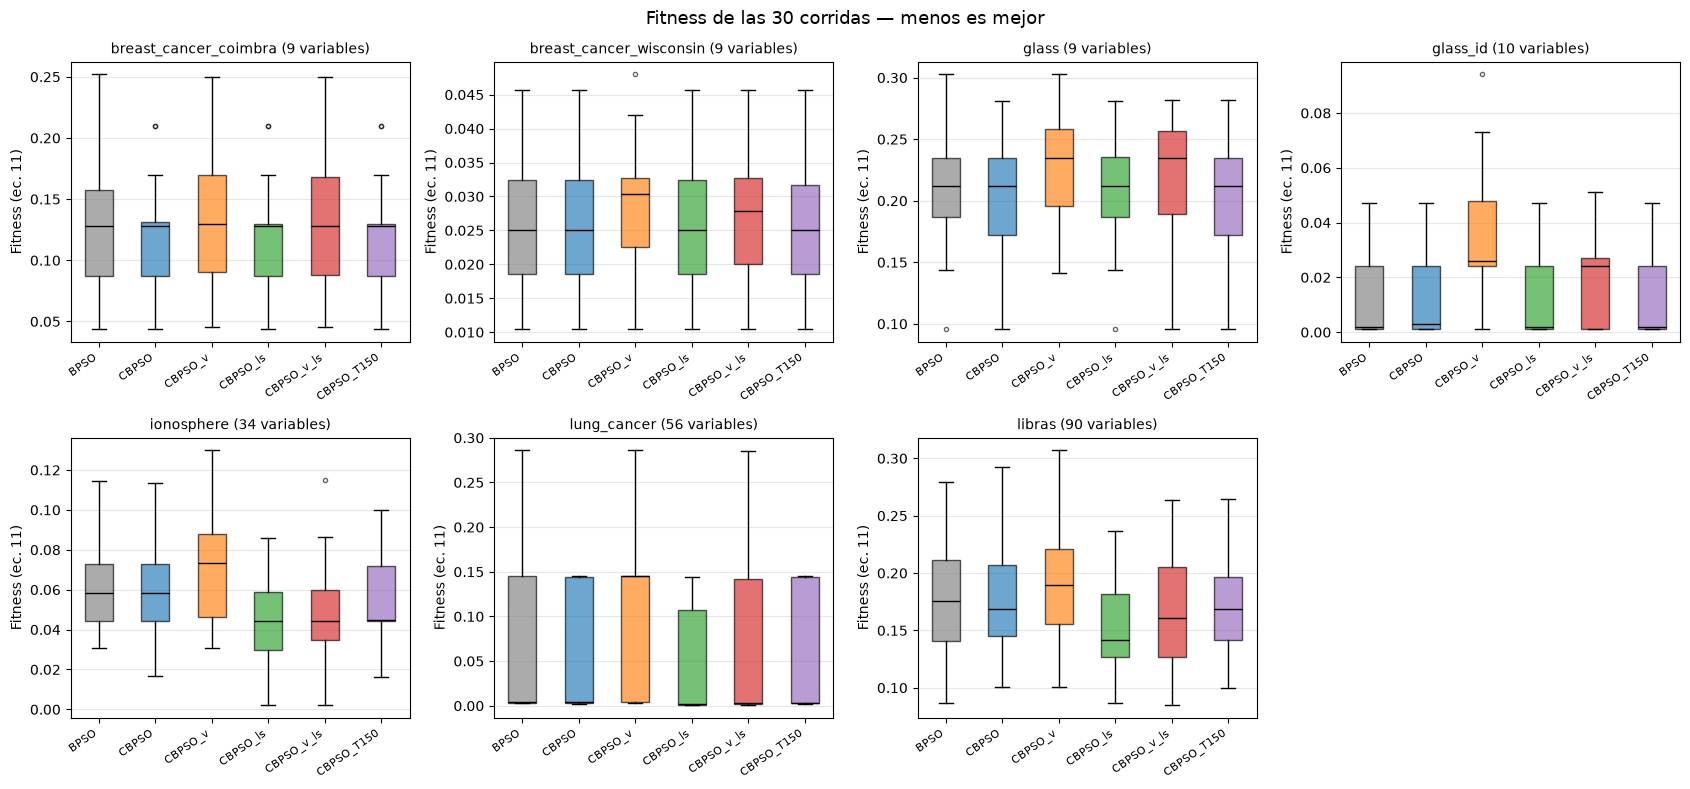

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, base in zip(axes.flat, BASES):
    datos = [df.loc[(df["dataset"] == base) & (df["method"] == m), "best_fitness"].to_numpy()
             for m in ORDEN]
    bp = ax.boxplot(datos, patch_artist=True, medianprops=dict(color="black"),
                    flierprops=dict(markersize=3, alpha=0.6))
    for caja, m in zip(bp["boxes"], ORDEN):
        caja.set(facecolor=COLOR[m], alpha=0.65)
    ax.set_xticks(range(1, len(ORDEN) + 1))
    ax.set_xticklabels([ETIQUETA[m] for m in ORDEN], rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{base} ({DIMS[base]} variables)", fontsize=10)
    ax.set_ylabel("Fitness (ec. 11)")
    ax.grid(axis="y", alpha=0.3)

axes.flat[-1].axis("off")
fig.suptitle("Fitness de las 30 corridas — menos es mejor", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "boxplots_fitness.png", dpi=300, bbox_inches="tight")
plt.show()

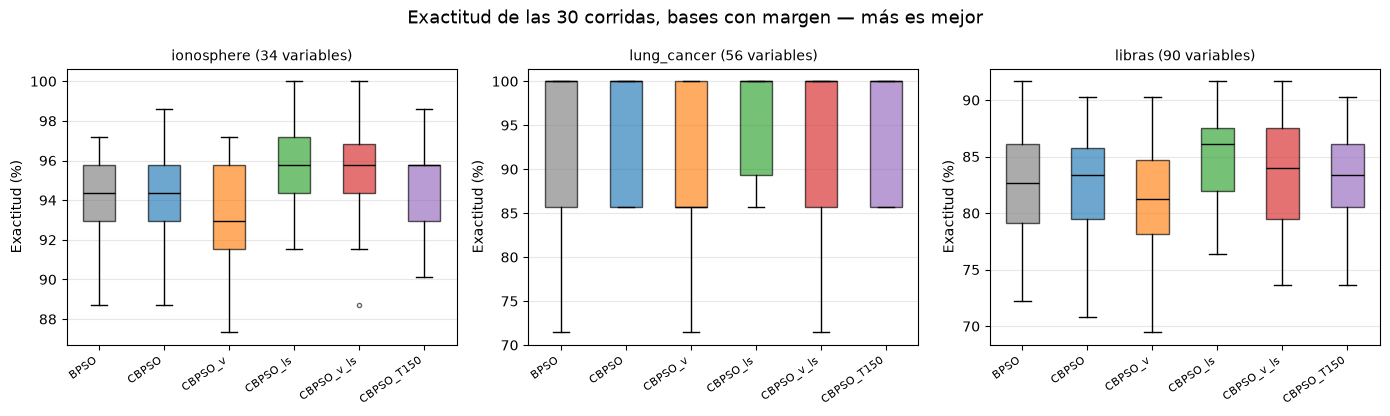

In [7]:
# Las tres bases con margen, en grande y con la exactitud (ec. 17)
CON_MARGEN = ["ionosphere", "lung_cancer", "libras"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=False)

for ax, base in zip(axes, CON_MARGEN):
    datos = [df.loc[(df["dataset"] == base) & (df["method"] == m), "accuracy"].to_numpy()
             for m in ORDEN]
    bp = ax.boxplot(datos, patch_artist=True, medianprops=dict(color="black"),
                    flierprops=dict(markersize=3, alpha=0.6))
    for caja, m in zip(bp["boxes"], ORDEN):
        caja.set(facecolor=COLOR[m], alpha=0.65)
    ax.set_xticks(range(1, len(ORDEN) + 1))
    ax.set_xticklabels([ETIQUETA[m] for m in ORDEN], rotation=35, ha="right", fontsize=8)
    ax.set_title(f"{base} ({DIMS[base]} variables)", fontsize=10)
    ax.set_ylabel("Exactitud (%)")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Exactitud de las 30 corridas, bases con margen — más es mejor", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "boxplots_exactitud.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Curvas de convergencia por **evaluaciones**

El eje x son **evaluaciones de la función de fitness**, no iteraciones. Es la única
comparación justa: `cbpso_miws_ls` gasta hasta `n_flips = 5` evaluaciones extra por
iteración, y `cbpso_miws_T150` corre 50 iteraciones más. En el eje de iteraciones la
búsqueda local parecería ganar "gratis".

`results/evals.npz` guarda, para cada corrida, las evaluaciones acumuladas al terminar
cada iteración (ver `bfs.experiment.evals_curve`). Como las corridas gastan cantidades
distintas, se promedia el fitness sobre una **malla común** de evaluaciones,
interpolando cada corrida por escalones (el mejor fitness solo cambia cuando mejora).

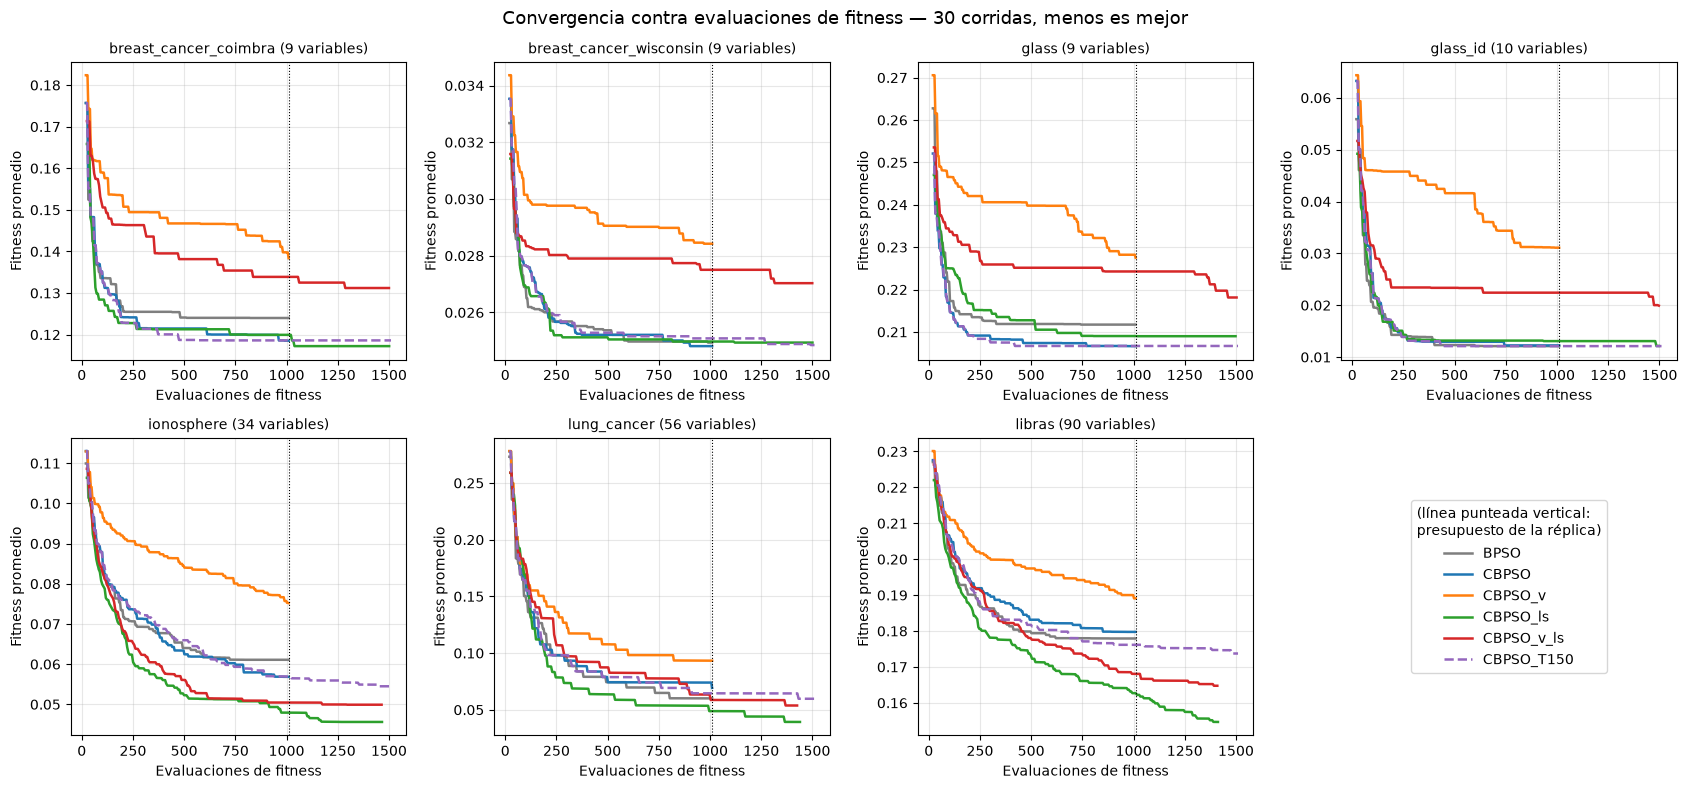

In [8]:
evaluaciones = {k: v for k, v in np.load(RESULTS / "evals.npz").items()}

def malla_y_curva(base, metodo, puntos=250):
    """Fitness promedio de las 30 corridas sobre una malla de evaluaciones.

    Cada corrida se interpola **por escalones**: entre dos iteraciones el mejor
    fitness no cambia, así que `np.searchsorted` da el valor exacto, no una
    aproximación.

    La malla llega hasta el presupuesto de la corrida más corta del método, de
    modo que el promedio siempre se calcula sobre las 30 corridas (nunca sobre
    un subconjunto, que sesgaría la cola de la curva). Por eso cada
    configuración se dibuja hasta donde honestamente alcanza: la réplica hasta
    ~1,010 evaluaciones, la búsqueda local hasta ~1,410 y el control hasta 1,510.
    """
    key = curve_key(base, metodo)
    fitness, evals = curvas[key], evaluaciones[key]
    # Empezar en el máximo de la 1ª iteración: por debajo de eso alguna corrida
    # daría índice -1 y numpy lo interpretaría como la ÚLTIMA iteración.
    malla = np.linspace(evals[:, 0].max(), evals[:, -1].min(), puntos)
    indices = [np.searchsorted(e, malla, side="right") - 1 for e in evals]
    assert all((i >= 0).all() for i in indices), "la malla cae antes de la 1ª iteración"
    promedio = np.mean([f[i] for f, i in zip(fitness, indices)], axis=0)
    return malla, promedio

fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, base in zip(axes.flat, BASES):
    for m in ORDEN:
        ax.plot(*malla_y_curva(base, m), label=ETIQUETA[m], color=COLOR[m], lw=1.8,
                ls="--" if m == "cbpso_miws_T150" else "-")
    ax.axvline(1010, color="black", lw=0.8, ls=":")
    ax.set_title(f"{base} ({DIMS[base]} variables)", fontsize=10)
    ax.set(xlabel="Evaluaciones de fitness", ylabel="Fitness promedio")
    ax.grid(alpha=0.3)

axes.flat[-1].axis("off")
axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), loc="center", fontsize=10,
                     title="(línea punteada vertical:\npresupuesto de la réplica)")
fig.suptitle("Convergencia contra evaluaciones de fitness — 30 corridas, menos es mejor",
             fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / "convergencia_evaluaciones.png", dpi=300, bbox_inches="tight")
plt.show()

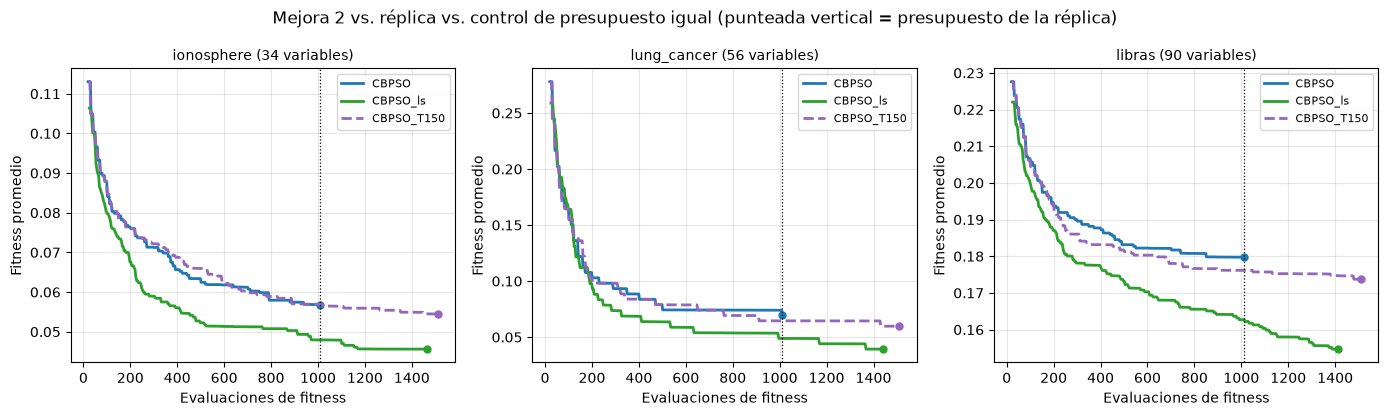

In [9]:
# Zoom en las tres bases con margen: la réplica, la mejora 2 y el control
FOCO = ["cbpso_miws", "cbpso_miws_ls", "cbpso_miws_T150"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, base in zip(axes, CON_MARGEN):
    for m in FOCO:
        malla, promedio = malla_y_curva(base, m, puntos=400)
        ax.plot(malla, promedio, label=ETIQUETA[m], color=COLOR[m], lw=2,
                ls="--" if m == "cbpso_miws_T150" else "-")
        ax.plot(malla[-1], promedio[-1], "o", color=COLOR[m], ms=5)  # fin del presupuesto
    ax.axvline(1010, color="black", lw=0.9, ls=":")
    ax.set_title(f"{base} ({DIMS[base]} variables)", fontsize=10)
    ax.set(xlabel="Evaluaciones de fitness", ylabel="Fitness promedio")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Mejora 2 vs. réplica vs. control de presupuesto igual "
             "(punteada vertical = presupuesto de la réplica)", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "convergencia_foco.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Costo vs. beneficio: ¿cuánto fitness se gana por evaluación extra?
costo = df.groupby("method", observed=True)[["n_evals", "best_fitness", "accuracy"]].mean()
ref = costo.loc["cbpso_miws"]
tabla = pd.DataFrame({
    "n_evals": costo["n_evals"].round(0),
    "Δ evals vs réplica": (costo["n_evals"] - ref["n_evals"]).round(0),
    "Δ fitness (↓ mejor)": (costo["best_fitness"] - ref["best_fitness"]).round(4),
    "Δ exactitud (↑ mejor)": (costo["accuracy"] - ref["accuracy"]).round(2),
}).reindex(ORDEN)
print("Promedio sobre las 7 bases:\n")
print(tabla.to_string())

print("\nSolo las 3 bases con margen (34, 56, 90 variables):\n")
con_margen = df[df["dataset"].isin(CON_MARGEN)]
c2 = con_margen.groupby("method", observed=True)[["n_evals", "best_fitness", "accuracy"]].mean()
r2 = c2.loc["cbpso_miws"]
print(pd.DataFrame({
    "n_evals": c2["n_evals"].round(0),
    "Δ evals vs réplica": (c2["n_evals"] - r2["n_evals"]).round(0),
    "Δ fitness (↓ mejor)": (c2["best_fitness"] - r2["best_fitness"]).round(4),
    "Δ exactitud (↑ mejor)": (c2["accuracy"] - r2["accuracy"]).round(2),
}).reindex(ORDEN).to_string())

Promedio sobre las 7 bases:

                 n_evals  Δ evals vs réplica  Δ fitness (↓ mejor)  Δ exactitud (↑ mejor)
method                                                                                  
bpso              1010.0                 0.0               0.0005                  -0.06
cbpso_miws        1010.0                 0.0               0.0000                   0.00
cbpso_miws_v      1010.0                 0.0               0.0164                  -1.61
cbpso_miws_ls     1491.0               481.0              -0.0094                   0.90
cbpso_miws_v_ls   1492.0               482.0              -0.0006                   0.03
cbpso_miws_T150   1510.0               500.0              -0.0026                   0.26

Solo las 3 bases con margen (34, 56, 90 variables):

                 n_evals  Δ evals vs réplica  Δ fitness (↓ mejor)  Δ exactitud (↑ mejor)
method                                                                                  
bpso              1010.0   

In [11]:
# ¿Con cuántas evaluaciones alcanza la mejora 2 el resultado final de la réplica?
filas = []
for base in CON_MARGEN:
    objetivo = malla_y_curva(base, "cbpso_miws")[1][-1]      # fitness final de la réplica
    malla, curva = malla_y_curva(base, "cbpso_miws_ls", puntos=2000)
    alcanzado = np.flatnonzero(curva <= objetivo)
    gasto = malla[alcanzado[0]] if alcanzado.size else np.nan
    filas.append({
        "base": base,
        "variables": DIMS[base],
        "fitness final réplica": round(float(objetivo), 4),
        "evals de la réplica": 1010,
        "evals que necesita la mejora 2": int(round(gasto)),
        "veces menos": round(1010 / gasto, 1),
    })
print(pd.DataFrame(filas).to_string(index=False))

       base  variables  fitness final réplica  evals de la réplica  evals que necesita la mejora 2  veces menos
 ionosphere         34                 0.0568                 1010                             367          2.8
lung_cancer         56                 0.0693                 1010                             324          3.1
     libras         90                 0.1798                 1010                             281          3.6


## 5. Conclusión

**¿La búsqueda local mejora?** Sí, donde hay margen. En `best_fitness` —lo que el
algoritmo realmente optimiza (ec. 11)— `cbpso_miws_ls` le gana a la réplica en
`ionosphere` (34 variables), `lung_cancer` (56) y `libras` (90), con Wilcoxon pareado
sobre 30 corridas y **sobreviviendo a la corrección de Holm**. En exactitud (ec. 17) la
ventaja sobrevive a Holm en `ionosphere` y `libras`; en `lung_cancer` no alcanza
significancia (p = 0.11 sin corregir) aunque la media suba de 93.3 % a 96.2 %. Tiene
sentido: con 32 instancias, el 20 % de prueba son 7 casos y la exactitud solo puede
moverse de 14.3 % en 14.3 %, así que es una métrica demasiado gruesa ahí; el fitness,
que es continuo, sí detecta la mejora. En las bases de 9–10
variables empata: con sólo 2⁹ = 512 subconjuntos posibles, la réplica ya encuentra el
óptimo en casi todas las corridas y no queda nada que explotar.

**¿A costa de cuántas evaluaciones?** De 1,010 a 1,491 en promedio (**+48 %**), nunca
más de 1,510 — exactamente el presupuesto del control `cbpso_miws_T150`, que iguala el
gasto con 50 iteraciones extra. Como la búsqueda local acepta la **primera** mejora,
muchas iteraciones cuestan menos de los 5 flips del tope. Y el punto clave: ese control
**no** le gana a la réplica después de Holm en ninguna base. Darle más iteraciones al
PSO no reproduce la mejora; la ganancia viene de *cómo* se gastan las evaluaciones
—refinando el Gbest— y no de gastar más. En la figura del punto 4 se ve que
`cbpso_miws_ls` ya va por debajo de las otras dos **antes** de agotar el presupuesto de
la réplica: según la tabla de arriba, le bastan entre 280 y 370 evaluaciones (**2.8× a
3.6× menos**) para llegar al fitness que la réplica alcanza con 1,010.

**¿Se complementan la V y la búsqueda local?** No. `cbpso_miws_v_ls` mejora mucho sobre
`cbpso_miws_v` sola —la búsqueda local rescata buena parte de lo que pierde la función
en V— pero se queda por debajo de `cbpso_miws_ls` en las tres bases con margen. Confirma
el diagnóstico de la etapa 1: a este algoritmo le falta explotación, no exploración.
Agregar las dos cosas a la vez diluye la mejora.

**¿Dónde hay margen?** El patrón es claro y es el mensaje del póster: **la mejora crece
con la dimensión**. Con 9–10 variables todas las variantes empatan; de 34 variables en
adelante la búsqueda local gana consistentemente. Esto también explica por qué las
comparaciones del artículo en bases chicas distinguen poco entre algoritmos.

> **Nota sobre `bpso`**: la línea base no queda significativamente por debajo de la
> réplica después de Holm en ninguna base (en `glass` queda peor sin corregir,
> p = 0.016, pero p_holm = 0.28). Con 30 corridas y este fitness, la ventaja de la
> co-evolución por sí sola es más chica de lo que sugiere el artículo. Es un resultado
> de la réplica, no de las mejoras; la etapa 3 lo contrasta con los números publicados.

In [12]:
print("Figuras guardadas en results/figures/ (300 dpi):")
for f in sorted(FIGURES.glob("*.png")):
    print(f"  {f.name}  ({f.stat().st_size / 1024:.0f} KB)")
print("\nTablas guardadas:")
for f in ("resumen.csv", "wilcoxon.csv"):
    print(f"  {f}")

Figuras guardadas en results/figures/ (300 dpi):
  boxplots_exactitud.png  (150 KB)
  boxplots_fitness.png  (364 KB)
  convergencia_evaluaciones.png  (699 KB)
  convergencia_foco.png  (278 KB)

Tablas guardadas:
  resumen.csv
  wilcoxon.csv
